# 02 · Modèle de prédiction des vols restants (RUL) — FD001

**Question métier :** combien de vols reste-t-il à chaque moteur avant qu'il faille le déposer ?

| # | Étape | Statut |
|---|---|---|
| 1 | Créer des variables qui résument l'histoire récente du moteur | ✅ |
| 2 | Mettre en place une validation par moteur | ✅ |
| 3 | Modèle de référence simple | ✅ |
| 4 | Modèle plus puissant | ✅ |
| 5 | Évaluer : erreur en vols + score asymétrique NASA | ✅ |
| 6 | Produire une fourchette d'incertitude (pour le stock) | ✅ |

> Après chaque bloc de code important, une cellule ✅ **Vérification** contrôle le résultat sur un cas connu. C'est une bonne pratique : on teste son code au lieu de supposer qu'il marche.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sys.path.append(str(Path.cwd().parent))
from src.data_loader import FIG_DIR, PROCESSED_DIR, SENSOR_LABELS

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

# On repart des données préparées dans le notebook 01
train = pd.read_csv(PROCESSED_DIR / "train_FD001.csv")
test = pd.read_csv(PROCESSED_DIR / "test_FD001.csv")
capteurs = pd.read_csv(PROCESSED_DIR / "capteurs_retenus.csv")["capteur"].tolist()

print(f"{len(capteurs)} capteurs : {capteurs}")
train.head(3)

12 capteurs : ['s11', 's4', 's12', 's7', 's15', 's21', 's20', 's17', 's2', 's3', 's8', 's13']


,unit,cycle,s11,s4,s12,s7,s15,s21,s20,s17,s2,s3,s8,s13,RUL,RUL_cap
0,1,1,47.47,1400.60,521.66,554.36,8.4195,23.4190,39.06,392,641.82,1589.70,2388.06,2388.02,191,125
1,1,2,47.49,1403.14,522.28,553.75,8.4318,23.4236,39.00,392,642.15,1591.82,2388.04,2388.07,190,125
2,1,3,47.27,1404.20,522.42,554.26,8.4178,23.3442,38.95,390,642.35,1587.99,2388.08,2388.03,189,125


---
## Étape 1 · Créer des variables

**Le problème :** une ligne = un vol. Si le modèle ne voit que les valeurs du vol actuel, il voit une photo bruitée, sans savoir d'où vient le moteur ni vers où il va.

**L'analogie :** un médecin à qui on donne une seule prise de température à 37,8 °C ne sait pas grand-chose. Si on lui dit « 36,8 il y a une semaine, et ça monte de 0,2 par jour », il sait.

On va donc fabriquer, pour chaque capteur, trois nouvelles variables :

| Variable | Question à laquelle elle répond |
|---|---|
| `_moy` : moyenne glissante sur 10 vols | « Quel est le niveau du capteur, sans le bruit ? » |
| `_delta` : écart à la référence du moteur | « Combien le moteur a-t-il dérivé depuis qu'il est neuf ? » |
| `_pente` : pente sur les 20 derniers vols | « À quelle vitesse ça se dégrade en ce moment ? » |

**Règle d'or : ne jamais utiliser le futur.** Chaque variable d'un vol ne doit utiliser que ce vol et les précédents. En vrai, au vol 50, on ne connaît pas le vol 51. Si on triche à l'entraînement, le modèle paraît excellent et s'effondre en service. C'est la **fuite de données** (*data leakage*), l'erreur n°1 en maintenance prédictive.

Les trois fonctions sont écrites **une seule fois**, dans `src/features.py`, parce que les notebooks suivants en ont aussi besoin. On les importe ici et on les applique une par une, avec une vérification après chacune. Leur code est recopié ci-dessous pour pouvoir le lire sans quitter le notebook.

In [2]:
from src.features import (
    ajouter_ecart_reference,
    ajouter_moyenne_glissante,
    ajouter_pente,
    construire_variables,
)

### 1.a — Moyenne glissante par moteur

Pour chaque capteur `s`, on crée une colonne `f"{s}_moy"` = moyenne des 10 derniers vols **du même moteur**.

```python
def ajouter_moyenne_glissante(df, capteurs, fenetre=FENETRE):
    df = df.copy()  # on ne modifie jamais le tableau d'origine
    for s in capteurs:
        par_moteur = df.groupby("unit")[s]
        df[f"{s}_moy"] = par_moteur.transform(lambda x: x.rolling(fenetre, min_periods=1).mean())
    return df
```

- `df.groupby("unit")[s].transform(...)` calcule moteur par moteur et renvoie une colonne de la même longueur que le tableau (vu au notebook 01).
- `x.rolling(fenetre, min_periods=1).mean()` : moyenne glissante sur une série `x`.
- `lambda x: ...` est une fonction écrite en une ligne : « la fonction qui prend `x` (ici, la série d'un moteur) et renvoie ... ».

**Pourquoi par moteur ?** Sans le `groupby`, les 10 premiers vols du moteur 2 seraient moyennés avec les derniers vols du moteur 1, juste avant sa panne. Ça n'a aucun sens physique.

In [3]:
train_f = ajouter_moyenne_glissante(train, capteurs)

# ✅ Vérification 1.a
r = train_f.query("unit == 1 and cycle == 100").iloc[0]
assert np.isclose(r["s11_moy"], 47.435, atol=1e-3), r["s11_moy"]
premier_vol = train_f.query("unit == 2 and cycle == 1").iloc[0]
assert premier_vol["s11_moy"] == premier_vol["s11"], "au 1er vol, la moyenne = la valeur brute"
print("OK ✅ moyenne glissante correcte")

OK ✅ moyenne glissante correcte


### 1.b — Écart à la référence du moteur

**Pourquoi :** Saxena et al. (2008) [1] expliquent que chaque moteur sort d'usine avec une petite usure initiale différente. Deux moteurs peuvent donc afficher des valeurs différentes alors qu'ils sont tous deux neufs. Plutôt que de comparer un moteur à la flotte, on le compare **à lui-même quand il était neuf**.

```python
def ajouter_ecart_reference(df, capteurs, n_ref=N_REFERENCE):
    df = df.copy()
    for s in capteurs:
        reference = df.groupby("unit")[f"{s}_moy"].transform(lambda x: x.iloc[:n_ref].mean())
        df[f"{s}_delta"] = df[f"{s}_moy"] - reference
    return df
```

Pour chaque capteur : `reference` = moyenne de `_moy` sur les 10 **premiers** vols du moteur (un nombre par moteur, recopié sur toutes ses lignes), puis `_delta` = `_moy` − `reference`.

**Note honnête sur la fuite de données :** pour les vols 1 à 9, la référence utilise quelques vols *suivants*. C'est négligeable ici : on prédit toujours au dernier vol observé, et les moteurs du test en ont au moins 31. Mais il faut savoir le dire si on pose la question.

In [4]:
train_f = ajouter_ecart_reference(train_f, capteurs)

# ✅ Vérification 1.b
r = train_f.query("unit == 1 and cycle == 100").iloc[0]
assert np.isclose(r["s11_delta"], 0.0843, atol=1e-3), r["s11_delta"]
debut = train_f.query("cycle <= 10").groupby("unit")["s11_delta"].mean()
assert np.allclose(debut, 0, atol=1e-9), "sur les 10 premiers vols, l'écart moyen doit valoir 0"
print("OK ✅ écart à la référence correct")

OK ✅ écart à la référence correct


### 1.c — La pente sur les 20 derniers vols

La pente répond à « à quelle vitesse ça bouge ». Mathématiquement, c'est la pente de la droite des moindres carrés (la régression linéaire simple) sur les 20 derniers points.

```python
def pente_glissante(x, fenetre=FENETRE_PENTE):
    """Pente de la droite des moindres carrés sur les derniers vols : cov(x, t) / var(t)."""
    t = pd.Series(np.arange(len(x)), index=x.index, dtype=float)  # le « temps » : 0, 1, 2...
    cov = x.rolling(fenetre, min_periods=2).cov(t)
    var = t.rolling(fenetre, min_periods=2).var()
    return (cov / var).fillna(0)  # au 1er vol, pas de pente possible -> 0
```

```python
def ajouter_pente(df, capteurs):
    df = df.copy()
    for s in capteurs:
        df[f"{s}_pente"] = df.groupby("unit")[s].transform(pente_glissante)
    return df
```

On utilise une formule de cours : **pente = covariance(capteur, temps) / variance(temps)**. Elle est calculée sur une fenêtre glissante, ce qui évite d'ajuster 20 000 régressions une par une.

In [5]:
train_f = ajouter_pente(train_f, capteurs)
print(f"Tableau final : {train_f.shape[0]:,} lignes x {train_f.shape[1]} colonnes")

Tableau final : 20,631 lignes x 52 colonnes


### Ce que ça change

Le graphique ci-dessous montre, pour le moteur 1 et le capteur Ps30 (s11) : la valeur brute, la moyenne glissante, l'écart à la référence et la pente. Le tableau mesure ensuite le lien de chaque version avec l'usure (Spearman, comme au notebook 01).

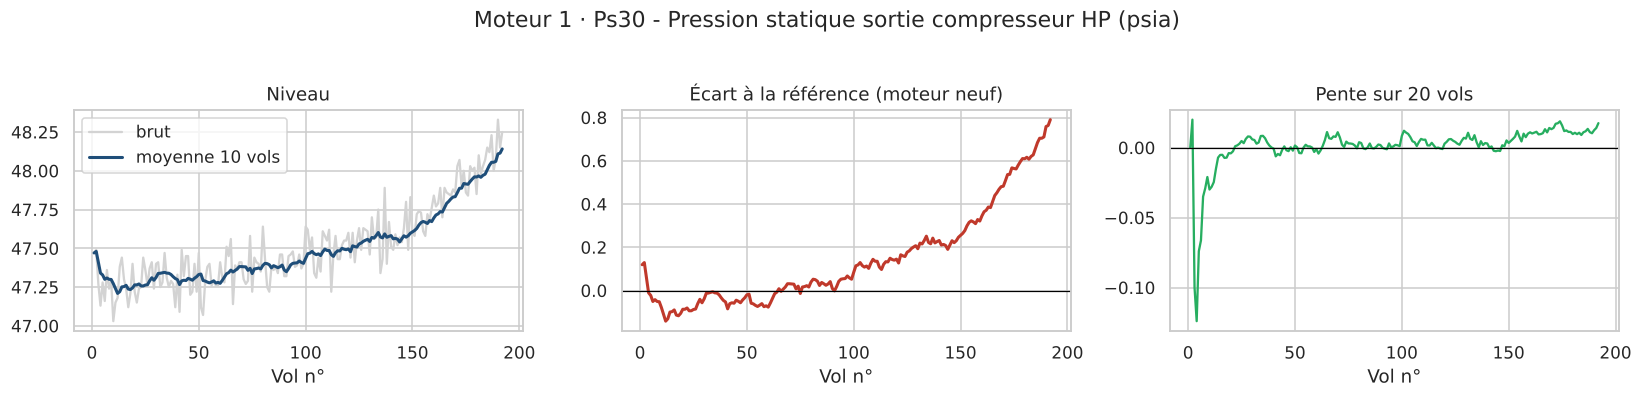

,|lien avec l'usure|
brut,0.720
moyenne,0.749
écart réf.,0.848
pente,0.508


In [6]:
s = "s11"
d = train_f[train_f["unit"] == 1]
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
axes[0].plot(d["cycle"], d[s], color="lightgrey", label="brut")
axes[0].plot(d["cycle"], d[f"{s}_moy"], color="#1f4e79", lw=2, label="moyenne 10 vols")
axes[0].set_title("Niveau")
axes[0].legend()
axes[1].plot(d["cycle"], d[f"{s}_delta"], color="#c0392b", lw=2)
axes[1].axhline(0, color="black", lw=0.8)
axes[1].set_title("Écart à la référence (moteur neuf)")
axes[2].plot(d["cycle"], d[f"{s}_pente"], color="#27ae60")
axes[2].axhline(0, color="black", lw=0.8)
axes[2].set_title("Pente sur 20 vols")
for ax in axes:
    ax.set_xlabel("Vol n°")
plt.suptitle(f"Moteur 1 · {SENSOR_LABELS[s]}", y=1.03)
plt.tight_layout()
plt.savefig(FIG_DIR / "08_variables_moteur1.png", bbox_inches="tight")
plt.show()

versions = {"brut": s, "moyenne": f"{s}_moy", "écart réf.": f"{s}_delta", "pente": f"{s}_pente"}
liens = {
    nom: train_f[col].corr(train_f["RUL_cap"], method="spearman") for nom, col in versions.items()
}
pd.Series(liens, name="|lien avec l'usure|").abs().round(3).to_frame()

> **Lecture :** l'écart à la référence gagne nettement (0,85 contre 0,72 pour le brut). Le lissage aide un peu (il enlève le bruit), mais le vrai gain vient de la comparaison du moteur **à lui-même** : on retire la différence de départ entre moteurs, qui brouillait le signal. La pente seule est plus faible, parce qu'elle est bruitée et ne dit rien du niveau d'usure déjà atteint. Elle reste utile *en complément* : à usure égale, un moteur qui se dégrade vite est plus urgent.

> **Pour le décideur :** on ne donne pas au modèle une photo du moteur, on lui donne son **historique résumé** : son niveau actuel, combien il a dérivé depuis qu'il est neuf, et à quelle vitesse il se dégrade. C'est exactement ce que fait un ingénieur EHM quand il suit une tendance de marge EGT [10].

---
## Étape 2 · Comment juger un modèle honnêtement : la validation par moteur

**Le principe :** on ne juge jamais un modèle sur les données qui ont servi à l'entraîner, sinon il « récite » au lieu de prédire. On découpe donc le train en 5 paquets : on entraîne sur 4, on teste sur le 5e, et on tourne 5 fois. C'est la **validation croisée**.

**Le piège :** si on découpe les **lignes** au hasard, le vol 150 du moteur 7 peut tomber à l'entraînement et le vol 151 du même moteur en validation. Avec des moyennes glissantes, ces deux lignes sont presque identiques. Le modèle « reconnaît » le moteur et paraît excellent. En service, il découvrira des moteurs qu'il n'a **jamais** vus, et il le sera beaucoup moins.

**La solution :** découper par **moteur entier** (`GroupKFold`). Un moteur est soit à l'entraînement, soit en validation, jamais les deux.

```
Découpage au hasard (FAUX)         Découpage par moteur (JUSTE)
moteur 7 : ██░██░░██░█             moteur 7 : █████████████  -> entraînement
moteur 8 : ░██░██░░███             moteur 8 : ░░░░░░░░░░░░░  -> validation
           █ entraînement  ░ validation
```

On le prouve ci-dessous avec le même modèle, validé des deux façons.

In [7]:
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.model_selection import GroupKFold, KFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

y = train_f["RUL_cap"]  # la cible : vols restants, plafonnés à 125
moteurs = train_f["unit"]  # le "groupe" de chaque ligne
par_moteur = GroupKFold(n_splits=5)  # 5 paquets de moteurs entiers


def rmse(pred, vrai):
    """Erreur type, en nombre de vols."""
    return float(np.sqrt(np.mean((np.asarray(pred) - np.asarray(vrai)) ** 2)))


def predictions_validation(modele, colonnes, decoupage=par_moteur, groupes=moteurs):
    """Prédit chaque ligne du train avec un modèle qui ne l'a JAMAIS vue
    (entraîné sur les 4 autres paquets). Les prédictions sont bornées entre 0 et 125."""
    # groups indique à GroupKFold quel moteur est sur chaque ligne
    p = cross_val_predict(modele, train_f[colonnes], y, cv=decoupage, groups=groupes)
    return np.clip(p, 0, 125)


def nouveau_gbm(**options):
    """Le modèle de l'étape 4 (expliqué plus bas), avec des réglages fixés pour être reproductible."""
    reglages = dict(max_iter=300, learning_rate=0.05, max_leaf_nodes=15, random_state=0)
    reglages.update(options)
    return HistGradientBoostingRegressor(**reglages)


# Toutes nos variables : 12 capteurs x (brut, moy, delta, pente) = 48 colonnes
VAR_TOUTES = [c for c in train_f.columns if c.startswith("s")]
print(f"{len(VAR_TOUTES)} variables")

48 variables


In [8]:
au_hasard = KFold(n_splits=5, shuffle=True, random_state=0)

err_hasard = rmse(predictions_validation(nouveau_gbm(), VAR_TOUTES, au_hasard, groupes=None), y)
# Prédictions gardées : elles resserviront aux étapes 4 et 5
pred_val = predictions_validation(nouveau_gbm(), VAR_TOUTES, par_moteur)
err_moteur = rmse(pred_val, y)

print(f"Validation au hasard : erreur type {err_hasard:5.1f} vols   <- trop beau pour être vrai")
print(f"Validation par moteur : erreur type {err_moteur:5.1f} vols   <- la vraie performance")

Validation au hasard : erreur type   8.7 vols   <- trop beau pour être vrai
Validation par moteur : erreur type  14.1 vols   <- la vraie performance


> **Lecture :** même modèle, mêmes données, et l'erreur paraît **40 % plus faible** quand on valide au hasard (environ 9 vols au lieu de 14). C'est une illusion : le modèle reconnaît des moteurs qu'il a déjà vus. **Toute la suite utilise la validation par moteur.**
>
> **Pour le décideur :** un chiffre de performance ne vaut que par la façon dont il a été mesuré. Si un prestataire annonce « 9 vols d'erreur » sans dire comment il a validé, il faut poser la question.

---
## Étape 3 · Des modèles de référence simples

Avant un modèle sophistiqué, on se donne des **points de comparaison**. Sinon, impossible de dire si 14 vols d'erreur, c'est bien ou mal.

| Modèle | Ce qu'il fait | Pourquoi l'essayer |
|---|---|---|
| **Naïf** | prédit toujours la même valeur : la RUL moyenne du train | le plancher absolu. Un modèle qui ne le bat pas ne sert à rien |
| **Régression linéaire (Ridge)** | une droite : RUL = a₁·capteur₁ + a₂·capteur₂ + … | simple, rapide, explicable. Le classique de l'économétrie |

**Ridge** est une régression linéaire avec une petite pénalité sur les coefficients. Elle évite qu'ils explosent quand les variables sont très corrélées entre elles, ce qui est notre cas (cf. heatmap du notebook 01). Le `StandardScaler` met d'abord toutes les variables à la même échelle, sinon la pénalité frapperait inégalement des capteurs en °R et en psia.

On teste aussi Ridge **avec les seuls capteurs bruts**, puis **avec nos 48 variables**, pour mesurer ce que l'étape 1 a apporté.

In [9]:
resultats = {}  # on garde tous les scores de validation dans un seul dictionnaire

resultats["Naïf (moyenne)"] = rmse(predictions_validation(DummyRegressor(), VAR_TOUTES), y)
ridge = lambda: make_pipeline(StandardScaler(), Ridge(alpha=1.0))
resultats["Ridge · capteurs bruts"] = rmse(predictions_validation(ridge(), capteurs), y)
resultats["Ridge · 48 variables"] = rmse(predictions_validation(ridge(), VAR_TOUTES), y)

pd.Series(resultats, name="erreur type (vols)").round(1).to_frame()

,erreur type (vols)
Naïf (moyenne),41.7
Ridge · capteurs bruts,22.4
Ridge · 48 variables,16.2


> **Lecture :** le naïf se trompe d'environ 42 vols en moyenne, c'est le plancher. La régression linéaire sur capteurs bruts descend autour de 22. Avec nos variables de l'étape 1, elle tombe vers 16 : **le travail sur les variables vaut plus que le choix du modèle**, c'est un enseignement classique.

---
## Étape 4 · Un modèle plus puissant : le gradient boosting

**L'idée en image :** un arbre de décision pose des questions en cascade, du type « l'écart de Ps30 est-il supérieur à 0,4 ? Si oui, la température T50 a-t-elle dérivé de plus de 5 ? ». Il découpe ainsi les moteurs en groupes et prédit la RUL moyenne de chaque groupe.

Le **gradient boosting** enchaîne 300 petits arbres. Chacun corrige les erreurs de tous les précédents : le 1er fait une prédiction grossière, le 2e apprend « de combien le 1er s'est trompé », le 3e corrige ce qui reste, etc.

**Pourquoi c'est adapté ici :**
- nos relations sont **en coude** (plat puis plongée), ce qu'une droite rate et que des arbres captent naturellement ;
- il gère les interactions (« telle température ET telle pression ») sans qu'on les écrive ;
- les variables corrélées ne le gênent pas ;
- c'est **le** modèle standard sur les données tabulaires en entreprise.

On utilise `HistGradientBoostingRegressor` de scikit-learn : rapide et sans dépendance supplémentaire.

**Réglages** (fixés dans `nouveau_gbm`) :
- `max_iter=300` : 300 arbres ;
- `learning_rate=0.05` : chaque arbre ne corrige que 5 % de l'erreur restante. On avance par petits pas, c'est plus prudent ;
- `max_leaf_nodes=15` : des arbres petits, chacun simple.

### 4.a · Quelles variables ? Trois jeux comparés

Promesse du notebook 01 : comparer nos 12 capteurs à la sélection de la littérature (7 capteurs, Ramasso & Saxena [3]).

In [10]:
VAR_LITTERATURE = [
    c for c in VAR_TOUTES if c.split("_")[0] in ["s2", "s3", "s4", "s7", "s11", "s12", "s15"]
]

resultats["Boosting · capteurs bruts"] = rmse(predictions_validation(nouveau_gbm(), capteurs), y)
resultats["Boosting · 7 capteurs littérature (28 var.)"] = rmse(
    predictions_validation(nouveau_gbm(), VAR_LITTERATURE), y
)
resultats["Boosting · 12 capteurs (48 var.)"] = (
    err_moteur  # déjà calculé à l'étape 2 (même modèle, même découpage)
)

pd.Series(resultats, name="erreur type (vols)").round(1).to_frame()

,erreur type (vols)
Naïf (moyenne),41.7
Ridge · capteurs bruts,22.4
Ridge · 48 variables,16.2
Boosting · capteurs bruts,21.1
Boosting · 7 capteurs littérature (28 var.),15.2
Boosting · 12 capteurs (48 var.),14.1


### 4.b · Les réglages comptent-ils ?

On essaie trois réglages raisonnables, **en validation uniquement**. Le jeu de test officiel reste sous clé : on ne le regardera qu'une fois, à l'étape 5. Sinon on finirait par choisir les réglages qui marchent sur le test, et le score final serait flatteur.

In [11]:
reglages_testes = {
    "pas 0.05 · 15 feuilles (retenu)": dict(learning_rate=0.05, max_leaf_nodes=15),
    "pas 0.05 · 31 feuilles": dict(learning_rate=0.05, max_leaf_nodes=31),
    "pas 0.10 · 31 feuilles": dict(learning_rate=0.10, max_leaf_nodes=31),
}
for nom, opts in reglages_testes.items():
    p = pred_val if "retenu" in nom else predictions_validation(nouveau_gbm(**opts), VAR_TOUTES)
    print(f"{nom:35s} erreur type {rmse(p, y):5.2f} vols")

pas 0.05 · 15 feuilles (retenu)     erreur type 14.15 vols


pas 0.05 · 31 feuilles              erreur type 14.23 vols


pas 0.10 · 31 feuilles              erreur type 14.36 vols


> **Lecture :** les écarts entre réglages sont de l'ordre de 0,2 vol, soit du bruit. On garde le plus simple (petits arbres). Ce qui compte vraiment, ce sont **les variables** (de 21 à 14 vols) et **la façon de valider** (9 contre 14). Les réglages fins du modèle, presque pas.

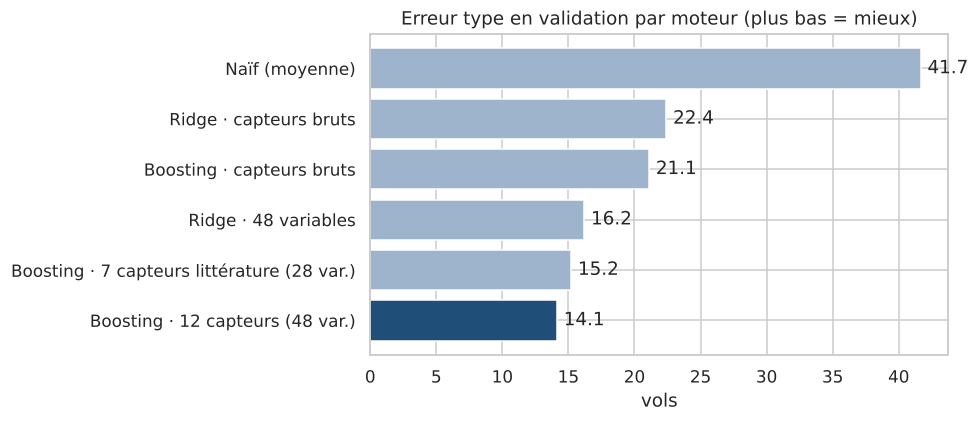

In [12]:
fig, ax = plt.subplots(figsize=(9, 4))
s = pd.Series(resultats).sort_values()
couleurs = [
    "#1f4e79" if k == "Boosting · 12 capteurs (48 var.)" else "#9db4cc" for k in s.index
]  # le modèle retenu en foncé
ax.barh(s.index, s.values, color=couleurs)
for i, v in enumerate(s.values):
    ax.text(v + 0.5, i, f"{v:.1f}", va="center")
ax.set(title="Erreur type en validation par moteur (plus bas = mieux)", xlabel="vols")
plt.tight_layout()
plt.savefig(FIG_DIR / "09_comparaison_modeles.png")
plt.show()

**Choix :** gradient boosting sur les 48 variables. Les 12 capteurs battent les 7 de la littérature (14,1 contre 15,2 vols) : les 5 capteurs en plus apportent de l'information. On les garde.

---
## Étape 5 · Le verdict : le jeu de test officiel

On entraîne le modèle final sur **tout** le train, puis on prédit les 100 moteurs du test. Ce sont des moteurs jamais vus, coupés avant la panne, comme une flotte en service.

**Point important :** on prédit au **dernier vol observé** de chaque moteur, puisque c'est la seule prédiction qui a du sens en exploitation (« aujourd'hui, combien lui reste-t-il ? »). Et on compare à la **vraie** RUL fournie par la NASA, sans plafond.

**Trois mesures :**
- **erreur type (RMSE)** : punit fort les grosses erreurs ;
- **erreur moyenne absolue (MAE)** : « en moyenne, on se trompe de X vols ». La plus parlante pour un décideur ;
- **score NASA** (Saxena et al. [1]) : asymétrique. Prédire **trop tard** (le moteur casse avant la date annoncée) coûte plus cher que trop tôt, et la pénalité grimpe de façon exponentielle. Plus bas = mieux.

In [13]:
def penalites(pred, vrai):
    """Pénalité NASA de chaque prédiction (challenge PHM08). d = prédit - vrai.
    d < 0 : prédiction en avance (prudente)   -> exp(-d/13) - 1
    d > 0 : prédiction en retard (dangereuse) -> exp(d/10) - 1, qui grimpe plus vite"""
    d = np.asarray(pred) - np.asarray(vrai)
    return np.where(d < 0, np.exp(-d / 13) - 1, np.exp(d / 10) - 1)


def score_nasa(pred, vrai):
    """Score officiel = somme des pénalités (plus bas = mieux)."""
    return float(penalites(pred, vrai).sum())


test_f = construire_variables(test, capteurs)  # les 3 étapes d'un coup (src/features.py)
dernier_vol = test_f.groupby("unit").tail(1).set_index("unit")  # son dernier vol observé
rul_vraie = dernier_vol["RUL"]

modele = nouveau_gbm().fit(train_f[VAR_TOUTES], y)
rul_predite = pd.Series(
    np.clip(modele.predict(dernier_vol[VAR_TOUTES]), 0, 125), index=dernier_vol.index
)

ridge_final = ridge().fit(train_f[VAR_TOUTES], y)
rul_ridge = np.clip(ridge_final.predict(dernier_vol[VAR_TOUTES]), 0, 125)
rul_naif = np.full(len(rul_vraie), y.mean())

bilan = pd.DataFrame(
    {
        "erreur type (vols)": [rmse(p, rul_vraie) for p in (rul_naif, rul_ridge, rul_predite)],
        "erreur moyenne (vols)": [
            np.mean(np.abs(p - rul_vraie)) for p in (rul_naif, rul_ridge, rul_predite)
        ],
        "score NASA": [score_nasa(p, rul_vraie) for p in (rul_naif, rul_ridge, rul_predite)],
    },
    index=["Naïf", "Ridge", "Gradient boosting"],
)
bilan.round(1)

,erreur type (vols),erreur moyenne (vols),score NASA
Naïf,43.1,35.9,33629.2
Ridge,16.8,14.0,442.3
Gradient boosting,15.8,11.9,385.9


In [14]:
# ✅ Vérification : 100 moteurs, une prédiction chacun, et le score recalculé "à la main" sur un moteur
assert len(rul_predite) == 100 and rul_predite.between(0, 125).all()
d = rul_predite.iloc[0] - rul_vraie.iloc[0]
attendu = np.exp(-d / 13) - 1 if d < 0 else np.exp(d / 10) - 1
assert np.isclose(score_nasa([rul_predite.iloc[0]], [rul_vraie.iloc[0]]), attendu)
print(
    f"OK ✅ moteur 1 : prédit {rul_predite.iloc[0]:.0f}, vrai {rul_vraie.iloc[0]}, pénalité {attendu:.2f}"
)

OK ✅ moteur 1 : prédit 124, vrai 112, pénalité 2.20


### Où en est-on par rapport à l'état de l'art ?

Meilleur résultat publié sur FD001 au moment de la revue de Ramasso & Saxena (2014) [3] : **erreur moyenne de 10 vols, score NASA de 216**.

In [15]:
mae = np.mean(np.abs(rul_predite - rul_vraie))
print(
    f"Notre modèle  : erreur moyenne {mae:4.1f} vols, score NASA {score_nasa(rul_predite, rul_vraie):5.0f}"
)
print("Benchmark 2014: erreur moyenne 10.0 vols, score NASA   216")

Notre modèle  : erreur moyenne 11.9 vols, score NASA   386
Benchmark 2014: erreur moyenne 10.0 vols, score NASA   216


> **Lecture honnête :** on est proches de l'état de l'art de 2014 sans l'égaler (environ 12 vols d'erreur moyenne contre 10), avec un modèle standard, sans deep learning et sans réglage poussé. Pour un décideur, la question n'est pas de gagner un concours mais de savoir **si l'erreur est acceptable pour planifier**. On regarde donc où le modèle se trompe.

,moteurs,erreur_moyenne,biais_moyen
zone,,,
critique (≤30),25,5.8,3.9
à surveiller (31-60),14,7.6,2.4
sain (61-100),28,15.3,0.9
très sain (>100),33,15.6,-9.5


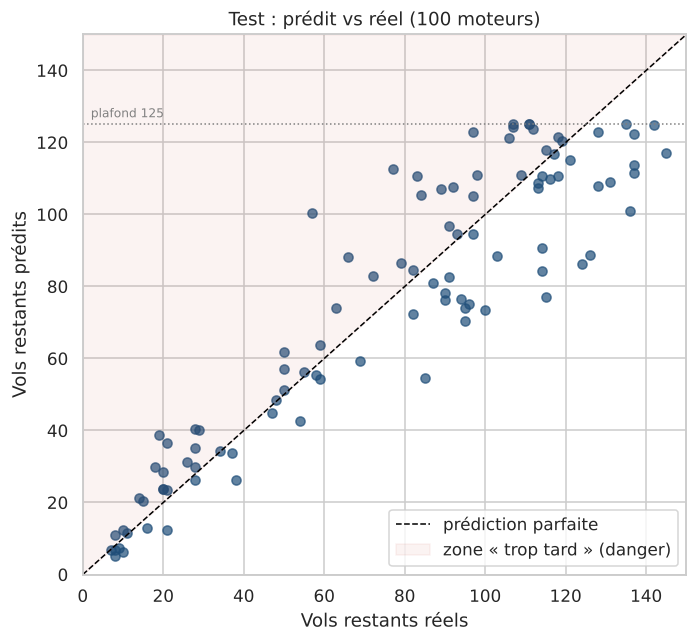

In [16]:
erreur = rul_predite - rul_vraie
zones = pd.cut(
    rul_vraie,
    bins=[0, 30, 60, 100, 200],
    labels=["critique (≤30)", "à surveiller (31-60)", "sain (61-100)", "très sain (>100)"],
)
par_zone = (
    pd.DataFrame({"zone": zones, "abs": erreur.abs(), "biais": erreur})
    .groupby("zone", observed=True)
    .agg(moteurs=("abs", "size"), erreur_moyenne=("abs", "mean"), biais_moyen=("biais", "mean"))
)
display(par_zone.round(1))

fig, ax = plt.subplots(figsize=(6.5, 6))
ax.scatter(rul_vraie, rul_predite, color="#1f4e79", alpha=0.7)
ax.plot([0, 150], [0, 150], color="black", ls="--", lw=1, label="prédiction parfaite")
ax.axhline(125, color="grey", ls=":", lw=1)
ax.text(2, 127, "plafond 125", color="grey", fontsize=8)
ax.fill_between(
    [0, 150], [0, 150], [150, 150], color="#c0392b", alpha=0.06, label="zone « trop tard » (danger)"
)
ax.set(
    xlabel="Vols restants réels",
    ylabel="Vols restants prédits",
    title="Test : prédit vs réel (100 moteurs)",
    xlim=(0, 150),
    ylim=(0, 150),
)
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig(FIG_DIR / "10_predit_vs_reel.png")
plt.show()

> **Lecture :**
> - **Moteurs critiques (≤ 30 vols) : environ 6 vols d'erreur.** C'est là que la précision compte, et c'est là que le modèle est le meilleur, conformément au plafonnement (notebook 01).
> - **Mais le biais est positif dans les zones critiques** : le modèle annonce en moyenne quelques vols de trop, c'est-à-dire **trop tard**. C'est le mauvais sens. On en tient compte à l'étape 6 : pour décider, on utilisera la **borne basse** de la fourchette, pas la valeur centrale.
> - **Moteurs très sains (> 100) : biais négatif d'environ 10 vols.** Normal : le modèle ne peut pas dépasser 125, alors que certains moteurs ont jusqu'à 145 vols devant eux. Sans conséquence métier, « au moins 125 vols » suffit pour ne rien faire.

### 5.b · Une marge de prudence fixe aiderait-elle ?

Idée naturelle : retirer quelques vols à toutes les prédictions pour éviter les retards. On choisit la marge **en validation** (avec le score NASA ligne à ligne), pas sur le test.

In [17]:
for marge in [0, 2, 4, 6, 8]:
    p = np.clip(pred_val - marge, 0, 125)
    print(
        f"marge {marge} vols : erreur type {rmse(p, y):5.2f}   pénalité NASA moyenne {penalites(p, y).mean():.3f}"
    )

marge 0 vols : erreur type 14.15   pénalité NASA moyenne 3.506
marge 2 vols : erreur type 14.43   pénalité NASA moyenne 3.436
marge 4 vols : erreur type 14.98   pénalité NASA moyenne 3.519
marge 6 vols : erreur type 15.75   pénalité NASA moyenne 3.746
marge 8 vols : erreur type 16.71   pénalité NASA moyenne 4.115


> **Lecture :** le meilleur compromis est une marge de 2 vols, mais le gain est minuscule. On **ne la garde pas** : elle complique le modèle pour presque rien. La prudence sera gérée plus proprement par la fourchette de l'étape 6.
>
> C'est aussi une leçon de méthode : **on a testé une idée, elle n'apporte pas assez, on l'écarte et on le documente.**

---
## Étape 6 · Une fourchette plutôt qu'un chiffre

**Pourquoi :** pour piloter le stock (notebook 04, méthode de Rodrigues & Yoneyama [8]), il ne suffit pas de dire « il reste 40 vols ». Il faut dire « il reste **entre 25 et 55 vols, avec 80 % de confiance** ». On en déduira la probabilité qu'un moteur soit à déposer avant l'arrivée d'une pièce commandée.

**Comment : la régression quantile.** Au lieu de viser la moyenne, on entraîne deux modèles :
- un modèle « **pessimiste** » qui vise le quantile 10 % : le moteur a 10 % de chances de durer moins que ça ;
- un modèle « **optimiste** » qui vise le quantile 90 %.

Entre les deux, il y a 80 % des cas, **si les modèles sont bien calibrés**.

**Le calibrage (méthode « conformal »).** On vérifie en validation combien de vrais moteurs tombent réellement dans la fourchette. S'il en tombe moins de 80 %, on élargit la fourchette de la petite quantité nécessaire. C'est une méthode récente et très utilisée, car elle garantit la couverture sans hypothèse compliquée.

In [18]:
quantile_modele = lambda q: nouveau_gbm(loss="quantile", quantile=q)

# 1) En validation par moteur : fourchettes brutes
#    (q10_brut, non borné, est gardé pour l'export de fin de notebook)
q10_brut = cross_val_predict(
    quantile_modele(0.10), train_f[VAR_TOUTES], y, cv=par_moteur, groups=moteurs
)
q10_val = np.clip(q10_brut, 0, 125)
q90_val = predictions_validation(quantile_modele(0.90), VAR_TOUTES)
couverture_brute = np.mean((y >= q10_val) & (y <= q90_val))

# 2) Calibrage : de combien la fourchette "rate" chaque vrai moteur (négatif = il est dedans)
depassement = np.maximum(q10_val - y, y - q90_val)
ajustement = np.quantile(depassement, 0.80)  # élargissement qui donne 80 % de couverture
couverture_ajustee = np.mean((y >= q10_val - ajustement) & (y <= q90_val + ajustement))

print(f"Couverture en validation avant calibrage : {couverture_brute:.0%}")
print(f"Élargissement nécessaire : {ajustement:.1f} vol de chaque côté")
print(f"Couverture en validation après calibrage : {couverture_ajustee:.0%}")

Couverture en validation avant calibrage : 78%
Élargissement nécessaire : 0.5 vol de chaque côté
Couverture en validation après calibrage : 80%


In [19]:
# 3) Sur le test : modèles entraînés sur tout le train, fourchette ajustée
modele_q10 = quantile_modele(0.10).fit(train_f[VAR_TOUTES], y)
modele_q90 = quantile_modele(0.90).fit(train_f[VAR_TOUTES], y)
bas = np.clip(modele_q10.predict(dernier_vol[VAR_TOUTES]) - ajustement, 0, 125)
haut = np.clip(modele_q90.predict(dernier_vol[VAR_TOUTES]) + ajustement, 0, 125)

# Les 3 modèles (bas, central, haut) sont entraînés séparément : il arrive, rarement, que la
# prédiction centrale sorte de la fourchette ("croisement de quantiles"). On force la cohérence.
bas = np.minimum(bas, rul_predite.values)
haut = np.maximum(haut, rul_predite.values)

# Le modèle ne peut pas dire plus que 125 : on compare donc à la vraie RUL plafonnée
vraie_plafonnee = rul_vraie.clip(upper=125).values
dedans = (vraie_plafonnee >= bas) & (vraie_plafonnee <= haut)
critiques = rul_vraie.values <= 60

print(f"Test : {dedans.mean():.0%} des moteurs dans leur fourchette (objectif 80 %)")
print(f"Test, moteurs à ≤ 60 vols : {dedans[critiques].mean():.0%} ({critiques.sum()} moteurs)")
print(f"Largeur moyenne de la fourchette : {np.mean(haut - bas):.0f} vols")

# ✅ Vérification : la prédiction centrale est toujours dans sa fourchette
assert np.all((bas <= rul_predite.values) & (rul_predite.values <= haut))
print("OK ✅ fourchettes cohérentes pour les 100 moteurs")

Test : 79% des moteurs dans leur fourchette (objectif 80 %)
Test, moteurs à ≤ 60 vols : 82% (39 moteurs)
Largeur moyenne de la fourchette : 32 vols
OK ✅ fourchettes cohérentes pour les 100 moteurs


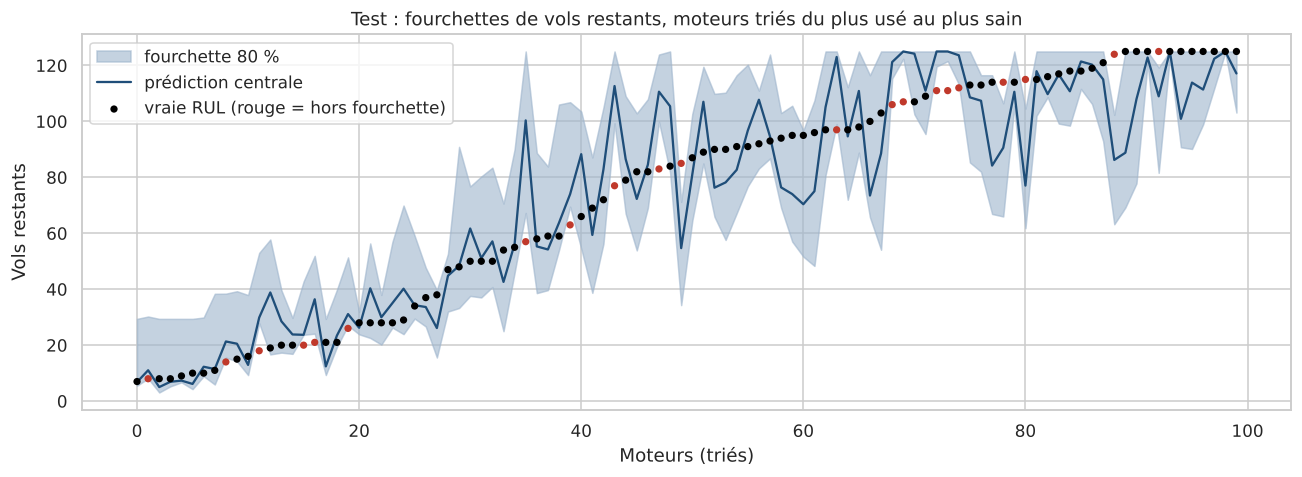

In [20]:
ordre = np.argsort(rul_vraie.values)
x = np.arange(100)
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.fill_between(x, bas[ordre], haut[ordre], color="#9db4cc", alpha=0.6, label="fourchette 80 %")
ax.plot(x, rul_predite.values[ordre], color="#1f4e79", lw=1.5, label="prédiction centrale")
ax.scatter(
    x,
    vraie_plafonnee[ordre],
    s=14,
    c=np.where(dedans[ordre], "black", "#c0392b"),
    zorder=3,
    label="vraie RUL (rouge = hors fourchette)",
)
ax.set(
    title="Test : fourchettes de vols restants, moteurs triés du plus usé au plus sain",
    xlabel="Moteurs (triés)",
    ylabel="Vols restants",
)
ax.legend(loc="upper left")
plt.tight_layout()
plt.savefig(FIG_DIR / "11_fourchettes_test.png")
plt.show()

> **Lecture :**
> - **La promesse est tenue** : environ 80 % des moteurs tombent dans leur fourchette, sur des moteurs jamais vus. Les quantiles étaient déjà presque bien calibrés, le recalage n'a élargi que d'environ 0,5 vol.
> - **Mais la fourchette est large, une trentaine de vols.** C'est l'incertitude réelle des données, et c'est précisément ce qu'il faut montrer au décideur plutôt qu'un chiffre unique faussement précis.
> - **Pour décider d'une dépose ou d'une commande, on utilisera la borne basse** : « avec 90 % de confiance, ce moteur tient au moins X vols ». C'est la réponse au biais « trop tard » vu à l'étape 5.

---
## Sauvegardes pour la suite

- **Les modèles entraînés** (`outputs/models/`) : le modèle central et ceux des deux bornes, réutilisables sans réentraîner.
- **Les prédictions du test** (`data/processed/`), pour les notebooks 03 (alertes) et 04 (stock).
- **Les prédictions « honnêtes » du train** (`data/processed/predictions_validation_FD001.csv`) : pour chaque vol de chaque moteur du train, la prédiction centrale et la borne basse faites par un modèle qui n'a jamais vu ce moteur. Les notebooks 03, 04 et 05 en ont tous besoin : on les calcule **une seule fois ici** au lieu de refaire la même validation croisée dans chacun.
- **Une table Power BI** `fact_predictions` : une ligne par moteur en service, avec prédiction, fourchette et vraie RUL. On la reliera à `dim_moteur` par `id_moteur`.

In [21]:
import joblib

from src.data_loader import POWERBI_DIR, PROJECT_ROOT

dossier_modeles = PROJECT_ROOT / "outputs" / "models"
dossier_modeles.mkdir(parents=True, exist_ok=True)
joblib.dump(
    {
        "modele": modele,
        "modele_q10": modele_q10,
        "modele_q90": modele_q90,
        "variables": VAR_TOUTES,
        "ajustement_fourchette": ajustement,
    },
    dossier_modeles / "gbm_rul_FD001.joblib",
)

# Prédictions honnêtes du train (validation par moteur), pour les notebooks 03, 04 et 05.
# Borne basse = quantile 10 % ajusté, jamais au-dessus de la prédiction centrale (comme sur le test).
validation = train_f[["unit", "cycle", "RUL"]].assign(
    rul_predite=pred_val,
    rul_basse=np.minimum(np.clip(q10_brut - ajustement, 0, 125), pred_val),
)
validation.to_csv(PROCESSED_DIR / "predictions_validation_FD001.csv", index=False)

predictions = pd.DataFrame(
    {
        "id_moteur": [f"TEST-{u:03d}" for u in dernier_vol.index],
        "vols_observes": dernier_vol["cycle"].values,
        "rul_predite": rul_predite.round(1).values,
        "rul_basse_80": bas.round(1),
        "rul_haute_80": haut.round(1),
        "rul_reelle": rul_vraie.values,
        "erreur": (rul_predite - rul_vraie).round(1).values,
    }
)
predictions.to_csv(PROCESSED_DIR / "predictions_test_FD001.csv", index=False)
predictions.to_csv(POWERBI_DIR / "fact_predictions.csv", index=False, sep=";", decimal=",")
predictions.head()

,id_moteur,vols_observes,rul_predite,rul_basse_80,rul_haute_80,rul_reelle,erreur
0,TEST-001,31,123.6,113.3,125.0,112,11.6
1,TEST-002,49,110.9,88.8,125.0,98,12.9
2,TEST-003,126,59.4,38.7,87.1,69,-9.6
3,TEST-004,106,72.3,53.9,102.9,82,-9.7
4,TEST-005,98,82.7,67.2,116.5,91,-8.3


## Synthèse pour le décideur

1. **Le modèle prédit les vols restants avec environ 12 vols d'erreur moyenne**, et **environ 6 vols sur les moteurs critiques** (≤ 30 vols), là où ça compte. C'est proche de l'état de l'art publié sur ces données (10 vols), avec un modèle standard et explicable.
2. **La performance a été mesurée honnêtement** : validation par moteur entier, test officiel regardé une seule fois. Une validation naïve aurait annoncé une erreur 40 % plus faible, mais illusoire.
3. **Ce qui fait la qualité du modèle, ce sont les variables** (comparer chaque moteur à lui-même, suivre sa tendance), bien plus que le choix de l'algorithme.
4. **Chaque prédiction vient avec une fourchette à 80 %**, vérifiée sur des moteurs jamais vus. Elle est large (une trentaine de vols) : c'est l'incertitude réelle, et on la montre plutôt que de la cacher.
5. **Point de vigilance** : près de la panne, le modèle a tendance à annoncer quelques vols de trop. Les décisions de dépose et de commande s'appuieront donc sur la **borne basse** de la fourchette.

**Étape suivante (notebook 03) :** transformer ces prédictions en **alertes** (« à déposer dans les 30 vols ? ») et vérifier les critères de Safran : moins de 5 % de fausses alertes, au moins 80 % de détection [10].